<a href="https://colab.research.google.com/github/suavejavi/Project-1-Data-201/blob/main/DATA_201_PROJECT_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data 201 Project 1

By: Javier Mantilla

#1. Understand Your Problem




In [ ]:
#mount Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold,KFold,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,recall_score, f1_score, roc_curve, roc_auc_score)
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')
heart = pd.read_csv("/content/drive/MyDrive/Data 201/Datasets/heart.csv")  # adjust path
heart.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
#Here we are looking at the shape of the dataset.
heart.shape


(1025, 14)

In [ ]:
#Looking at the each variable type.
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
#Here I made a frequency table and I looked at the values for each of my predictors.
heart[["age", "sex", "trestbps", "chol"]]

,age,sex,trestbps,chol
0,52,1,125,212
1,53,1,140,203
2,70,1,145,174
3,61,1,148,203
4,62,0,138,294
...,...,...,...,...
1020,59,1,140,221
1021,60,1,125,258
1022,47,1,110,275
1023,50,0,110,254


In [ ]:
#Here I looked at the distribution of my target variable.
heart["target"].value_counts()

,count
target,
1,526
0,499


#1. Understand Your Problem

1. Each row of my dataset represents a patient who has undergone testing for heart disease. Our response variable is the "target" variable. Our response variable is binary, with "0" meaning the patient does not have heart disease and "1", meaning the patient does have heart disease.

2. The predictors I chose that I think could be useful for classification are "age" (The patient's age), "sex"(The patients sex), "trestbps"(The paitent's resting blood pressure), and "chol" (The patients cholesterol). I believe all of these predictors could be useful for classification because they can all influence whether or not one gets heart disease.

3. The distribution of our response variable is pretty balanced. When I did value_counts, we say that 499 reported to not have heart disease, and 526 reported to have heart disease. Since our split is almost 50/50, we will not have to stratify our data when we split it.

4. A false positive in the context of my dataset is when we predict heart disease is present, but the patient is actually healthy. A false negative in the context of my dataset is when we predict heart disease absent, but the patient is actually sick.

5. I would be much more concerned about a false negative rather than a false positve, becausse if a patient is classified as healthy, when they actually have heart disease, the paitent will go home without lifesaving treatment, meaning that the paitient's chance of a fatal cardiovascular event will go up severly.

#2. Explore and Prepare the Data


#Investigate Features and Predictors

###Here I am going to create boxplots and countplots of my predictors and target variables to look for varaition, and to justify why I chose these predictors.

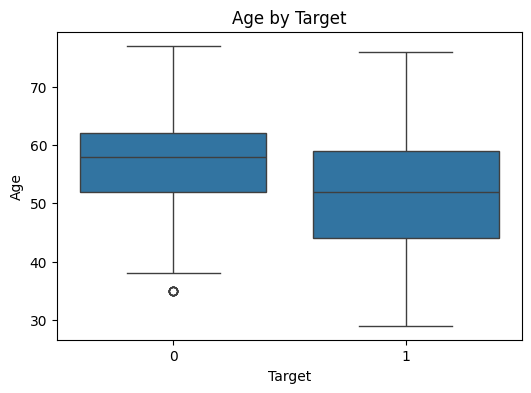

In [ ]:

#Investigate features and predictors
#Here I am going to create boxplots and countplots of my predictors and target variables to look for varaition, and to justify why I chose these predictors.

plt.figure(figsize=(6, 4))
sns.boxplot(data=heart, x='target', y='age')
plt.title('Age by Target')
plt.xlabel('Target')
plt.ylabel('Age')
plt.show()

This boxplot is looking into how age is related to the target variable. This boxplot shows that for when the patients have heart disease (1), the whiskers are longer in the boxplot. This means that there is a wider age range for people with heart disease than without. Also, the median age is greater for people without heart disease which was fairly interesting to me. Seeing these two instances in the graph is the reason why I am keeping age as I believe it will be a useful predictor.



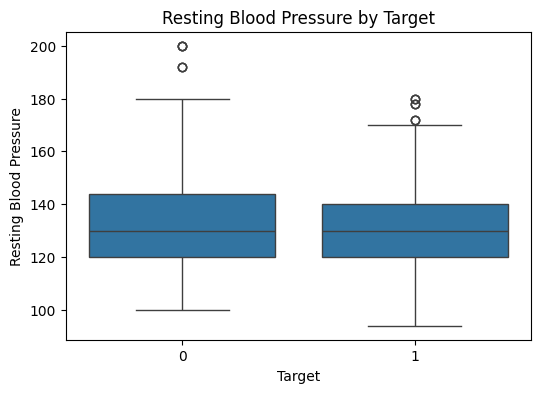

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=heart, x='target', y='trestbps')
plt.title('Resting Blood Pressure by Target')
plt.xlabel('Target')
plt.ylabel('Resting Blood Pressure')
plt.show()

This boxplot is looking into how resting blood pressure is related to the target variable. This boxplot shows that for when the patients have heart disease (1), the whiskers of the boxplot are shorter, which means that the resting blood pressure has a smaller amount of variation, even with some outliers around 180. According to the American Heart Association, normal resting blood pressure is anything less than 120. Elevated is 120-129. Stage 1 hypertension is 130-139. Stage 2 hypertension is 140 or higher. Severe hypertension/hypertension emergency is higher than 180. Our boxplot shows the median resting blood pressure is around 130 for both heart disease being present or absent, meaning that the median for both groups show an eleveted resting blood pressure. This is why I am keeping resting blood pressure as I believe this elevated resting blood pressure will be key to a useful predictor.

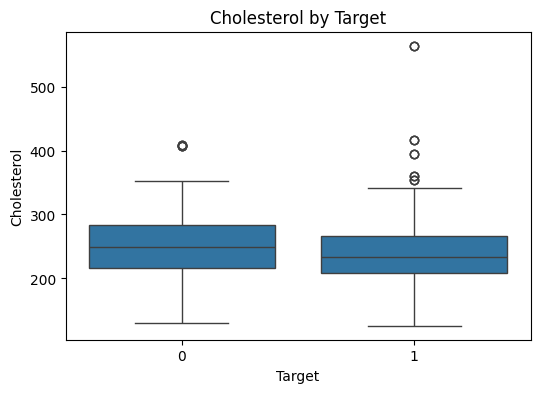

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=heart, x='target', y='chol')
plt.title('Cholesterol by Target')
plt.xlabel('Target')
plt.ylabel('Cholesterol')
plt.show()

This boxplot is looking into how serum or total cholesterol is related to the target variable. This boxplot shows that the paitents with heart disease have a lower median cholesterol, which is very surprising to me as I thought that it would've been much higher. This is kind of supported by the outliers, as there are a few that are oushing 400 or 500 mg/dl, which is life threatening. This led me to believe that the paitents may have been put on medicine that lowers cholestoral when being admitted to the hospital. This is why I am keeping cholestoral as a useful predictor.

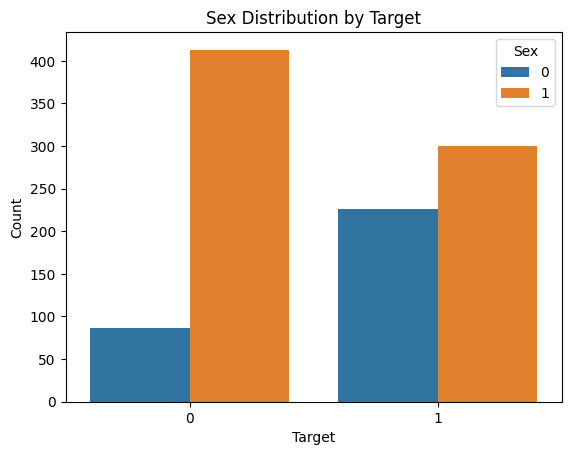

In [ ]:


sns.countplot(data=heart, x='target', hue='sex')

plt.title('Sex Distribution by Target')
plt.xlabel('Target')
plt.ylabel('Count')
plt.legend(title='Sex')
plt.show()

This countplot is looking into the relationship between the sex of the patient and the target variable. The countplot shows that males (Sex 1) make up almost all of the healthy patients. This was surprising to me as I thought that it would be more of a 50/50 split, however, this tells us that females are more likely to be diagnosed with heart disease, proportionally. This is because a much higher percentage of females falls into the heart disease category, rather than the healthy category. This is why I am keeping sex as a useful predictor.

In [ ]:
#Now we will check if our data has any NA's or missing values.
heart.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


We have no NA/missing values.

In [ ]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


The code above shows that all of my variables, and all of my predictors are numerical which means we do not have to encode any of them.

In the code below, we will check if we have to standardize any of our predictors.

In [ ]:
heart.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


This dataframe tells us that we will need to standardize our numeric predictors. This is because our maximum for cholesterol is 564, and our maximum for sex is 1. (0 or 1 because its binary). We will still need to standardize it, as the maximum for age is 77 as well, which provides more reasons to standardize.

In [ ]:
#Now we will split, standardize,and complete k-fold cross validation.

X = heart[["sex", "age", "trestbps", "chol"]]
y = heart["target"]

numeric_features = ["age", "chol", "trestbps", "sex"]


#Split the data: 75% training and 25% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=67
)

# Build preprocessing steps
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
])

# Combine preprocessing with pipeline

def pipeline(model):
  heart_pipe = make_pipeline(
      preprocess,
      model
  )
  return heart_pipe

# K-fold Cross Validation
kfold5 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=67
)

def cross_validation(model):
  raw_cv = cross_val_score(
      pipeline(model),
      X_train,
      y_train,
      cv=kfold5,
      scoring="accuracy")
  return raw_cv.mean()


#2. Explore and Prepare the Data

1. I investigated our features and predictors by creating 3 boxplots and 1 counplot. Our boxplot for age showed a wider range of ages of paitents with heart disease than without. Our boxplot for resting blood pressure showed us that the median for both paitents with or without heart disease is elevated, per the American Heart Association. Our boxplot for cholestoral showed us paitents with heart disease had a lower median cholestoral, which makes me think that they may have been put on cholestoral reducing medicine when being admitted to the hospital. Our countplot for sex showed us that males make up most of the healthy patients, and females are more likely to have heart disease proportionally as a much higher percentage of the females fall into the disease category.

2. I added up the missing values from each variable and we got 0 NA/Missing values.

3. I did heart.info(), and noticed that we do not need to encode any of my variables.

4. First, I used train_test_split to split my dataset into 75% training and 25% testing. Then I used ColumnTransformer, with StandardScaler to standardize my numerical predictors, which I then combined into a pipeline.Lastly, I created another fuction that calculates the average accurace of the model. We also passed the model through our pipeline and cross_val_score, which standardized the data.
5. I determined that we will need to standardize all of our numerical predictors because when I did heart.describe(), it gave us a dataframe with all of the values we may need for the variables. We saw that the maximum for cholesterol was 564, and it's standard deviation was 51, and the maximum for age was 77, with its standard deviation being 9. With this huge gap, I decided that it was neccesary to standardize the numerical predictors.

#3. Build Your Classifiers

#3a. Logistic Regression

In [ ]:
print(cross_validation(LogisticRegression(max_iter=5000)))
logreg = pipeline(LogisticRegression(max_iter=5000))
logreg.fit(X_train, y_train)

logreg_pred = logreg.predict(X_test)
logreg_prob = logreg.predict_proba(X_test)[:, 1]
print(logreg_pred[:5])
print(logreg_prob[:5])

0.6536796536796536
[0 0 0 0 1]
[0.16760631 0.24082899 0.48161322 0.34845248 0.63342833]


#3b. LDA

In [ ]:
print(cross_validation(LinearDiscriminantAnalysis()))
lda = pipeline(LinearDiscriminantAnalysis())
lda.fit(X_train, y_train)

lda_pred = lda.predict(X_test)
lda_prob = lda.predict_proba(X_test)[:, 1]
print(lda_pred[:5])
print(lda_prob[:5])

0.6536796536796536
[0 0 0 0 1]
[0.16520201 0.23781527 0.47452061 0.34325054 0.63049586]


#3c. QDA

In [ ]:
print(cross_validation(QuadraticDiscriminantAnalysis()))
qda = pipeline(QuadraticDiscriminantAnalysis())
qda.fit(X_train, y_train)

qda_pred = qda.predict(X_test)
qda_prob = qda.predict_proba(X_test)[:, 1]
print(qda_pred[:5])
print(qda_prob[:5])

0.6667006196417962
[0 0 1 0 1]
[0.21670079 0.29563711 0.52588047 0.29265215 0.58023029]


#3d. KNN


In [ ]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

knn_grid = {
    'kneighborsclassifier__n_neighbors': [5, 7, 9, 11, 13, 15, 21, 25, 31, 33, 35, 41, 55, 72, 77, 99],
    'kneighborsclassifier__weights': ['uniform']
}

grid_knn = GridSearchCV(
    knn,
    knn_grid,
    cv=kfold5,
    scoring = 'accuracy'
)

grid_knn.fit(X_train, y_train)
print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV Accuracy:", round(grid_knn.best_score_, 4))

KNN best parameters: {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'uniform'}
KNN best CV Accuracy: 0.7252


In [ ]:
#Test these possible values
k_values = [5, 7, 9, 11, 13, 15, 21, 25, 31, 33, 35, 41, 55, 72, 77, 99]

#create an empty list
cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold5,
        scoring = 'accuracy'
    )

    cv_scores.append(scores.mean())

print(cv_scores)

[np.float64(0.6783464901111961), np.float64(0.7252270605211782), np.float64(0.7083269671504965), np.float64(0.6900517782870723), np.float64(0.6965707495119261), np.float64(0.6874883286647993), np.float64(0.6939648586707412), np.float64(0.6888464476699772), np.float64(0.6822765469824292), np.float64(0.6770308123249299), np.float64(0.6914014090484679), np.float64(0.6797130973601562), np.float64(0.6640862405568287), np.float64(0.6731771496477379), np.float64(0.683583736524913), np.float64(0.6783804430863254)]


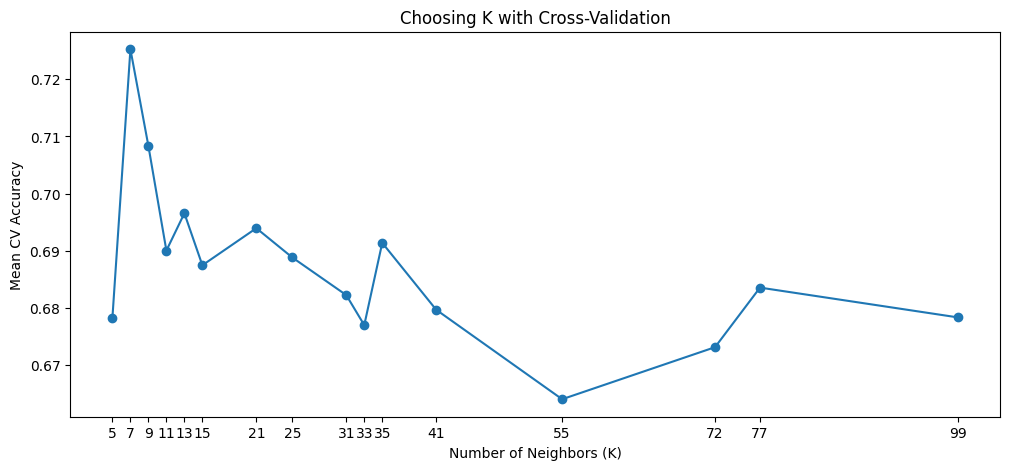

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xticks(k_values)
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("Choosing K with Cross-Validation")

plt.show()

In [ ]:
best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=7)
)

#fit
best_knn.fit(X_train, y_train)

#predict
best_knn_pred = best_knn.predict(X_test)

#evaluate
accuracy_score(y_test, best_knn_pred)
best_knn_prob = best_knn.predict_proba(X_test)[:, 1]
print(best_knn_pred[:5])
print(best_knn_prob[:5])

[1 0 0 0 0]
[1.         0.42857143 0.28571429 0.         0.28571429]
0.754863813229572


#3. Build Your Classifiers

1. Logistic Regression, LDA and QDA

For logistic regression, LDA and QDA, I used the Standard Scaler and the Model and put them into one pipeline, and I fit it on the training data. Then I used predict for the predictions if they didnt or did have heart disease (0/1), and predict_proba for the probability of heart disease on the test data. I also used 5-fold cross-validation on the training data to get each model’s average accuracy

2. KNN

For KNN, I used GridSearchCV to test several values of K with 5-fold CV, and plotted the values that we tested with GridSearch, and saw K = 7 as the peak. I then refit KNN with K = 7 and generated test predictions and probabilities the same way. I used uniform weights instead of distance weights. When I first tried distance weighting, the test confusion matrix showed perfect scores, which seemed unrealistic. Also, the mean accuracy was only slightly higher, and with the results from the confusion matrix I determined that my dataset and the distance weighting will not work, which is why I chose uniform weighting.

##3. Which Classifier fits the best based on the training data?

Looking at the mean accuracies on the 5-fold cv training data, logistic regression and LDA both had a mean accuracy of 0.654, and QDA had a mean accuracy of 0.667, which I believe is too small of a gap to call meaningful. KNN with K = 7 scored a mean accuracy of 0.725, and we chose K = 7 with the help of GridSearch and the graph, where 7 was the peak, so KNN performed best on the training data. So, if I had to pick which classifier fits the best based on the training data, it would be KNN with K = 7.

#4. Evaluate Your Models

#4a. Logistic Regression

In [ ]:
#Threshold = 35%
logreg_pred = np.where(
    logreg_prob >= 0.35,
     1,
     0
)

#Confusion Matrix
cm = confusion_matrix(
    y_test,
    logreg_pred,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)



[[ 46  76]
 [  8 127]]
TN: 46
FP: 76
FN: 8
TP: 127


In [ ]:
accuracy = accuracy_score(
    y_test,
    logreg_pred
)

precision = precision_score(
    y_test,
    logreg_pred,
    pos_label= 1
)

recall = recall_score(
    y_test,
    logreg_pred,
    pos_label= 1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    logreg_pred,
    pos_label= 1
)
logreg_test_roc_auc = roc_auc_score(y_test, logreg_prob)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("Logistic Regression ROC-AUC:", logreg_test_roc_auc)


Accuracy: 0.6731517509727627
Precision: 0.625615763546798
Recall: 0.9407407407407408
Specificity: 0.3770491803278688
F1: 0.7514792899408284
Logistic Regression ROC-AUC: 0.7449908925318761


#4b. LDA

In [ ]:
#Threshold = 35%
lda_pred = np.where(
    lda_prob >= 0.35,
     1,
     0
)

#Confusion Matrix
cm = confusion_matrix(
    y_test,
    lda_pred,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 49  73]
 [ 10 125]]
TN: 49
FP: 73
FN: 10
TP: 125


In [ ]:
accuracy = accuracy_score(
    y_test,
    lda_pred
)

precision = precision_score(
    y_test,
    lda_pred,
    pos_label= 1
)

recall = recall_score(
    y_test,
    lda_pred,
    pos_label= 1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    lda_pred,
    pos_label= 1
)
lda_test_roc_auc = roc_auc_score(y_test, lda_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("LDA ROC-AUC:", lda_test_roc_auc)


Accuracy: 0.6770428015564203
Precision: 0.6313131313131313
Recall: 0.9259259259259259
Specificity: 0.4016393442622951
F1: 0.7507507507507507
LDA ROC-AUC: 0.7449908925318762


##4c. QDA

In [ ]:
#Threshold = 35%
qda_pred = np.where(
    qda_prob >= 0.35,
     1,
     0
)

#Confusion Matrix
cm = confusion_matrix(
    y_test,
    qda_pred,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 72  50]
 [ 33 102]]
TN: 72
FP: 50
FN: 33
TP: 102


In [ ]:
accuracy = accuracy_score(
    y_test,
    qda_pred
)

precision = precision_score(
    y_test,
    qda_pred,
    pos_label= 1
)

recall = recall_score(
    y_test,
    qda_pred,
    pos_label= 1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    qda_pred,
    pos_label= 1
)
qda_test_roc_auc = roc_auc_score(y_test, qda_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("QDA ROC-AUC:", qda_test_roc_auc)

Accuracy: 0.6770428015564203
Precision: 0.6710526315789473
Recall: 0.7555555555555555
Specificity: 0.5901639344262295
F1: 0.710801393728223
QDA ROC-AUC: 0.7671523982999393


##4d. KNN

In [ ]:
#Threshold = 35%
best_knn_pred = np.where(
    best_knn_prob >= 0.35,
     1,
     0
)

#Confusion Matrix
cm = confusion_matrix(
    y_test,
    best_knn_pred,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 63  59]
 [ 24 111]]
TN: 63
FP: 59
FN: 24
TP: 111


In [ ]:
accuracy = accuracy_score(
    y_test,
    best_knn_pred
)

precision = precision_score(
    y_test,
    best_knn_pred,
    pos_label= 1
)

recall = recall_score(
    y_test,
    best_knn_pred,
    pos_label= 1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    best_knn_pred,
    pos_label= 1
)
knn_test_roc_auc = roc_auc_score(y_test, best_knn_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("KNN ROC-AUC:", knn_test_roc_auc)

Accuracy: 0.6770428015564203
Precision: 0.6529411764705882
Recall: 0.8222222222222222
Specificity: 0.5163934426229508
F1: 0.7278688524590164
KNN ROC-AUC: 0.8159987856709168


#4. Evaluate Your Models

For all 4 of our models, I produced a confusion matrix, and the accuracy, precision, recall, specificity F1 and the roc_auc for each model. We will need to look into the amount of false negatives in the confusion matrix and the recall score, as those will matter the most in the context of our dataset.

##Threshold
I used a threshold of 0.35 for all four models, meaning that a patient is predicted to have heart disease if the model's predicted probability is 0.35 or higher. I chose a cutoff below the default of 0.50 because a false negative (sending home a patient who has heart disease) is more serious than a false positive (a healthy patient who gets extra testing). Lowering the threshold will help us catch more true cases. I chose 0.35 instead of something lower like 0.30 because it kept recall high for logistic regression and LDA, while reducing the number of healthy patients who were flagged (for logistic regression, false positives dropped from 88 to 76 while false negatives only rose from 6 to 8). I used the same threshold for every model so the comparison would be fair. I picked this threshold after looking at the test results, so it showed that I hypertuned my threshold.

#5. Reflect

##Threshold Choice

I used a threshold of 0.35 for all four models, meaning that a patient is predicted to have heart disease if the model's predicted probability is 0.35 or higher. I chose a cutoff below the default of 0.50 because a false negative (sending home a patient who has heart disease) is more serious than a false positive (a healthy patient who gets extra testing). Lowering the threshold will help us catch more true cases. I chose 0.35 instead of something lower like 0.30 because it kept recall high for logistic regression and LDA, while reducing the number of healthy patients who were flagged (for logistic regression, false positives dropped from 88 to 76 while false negatives only rose from 6 to 8). I used the same threshold for every model so the comparison would be fair. I picked this threshold after looking at the test results, so it showed that I hypertuned my threshold.  

##Recall and Specificity by Model


At my chosen threshold of 0.35, all four models had almost the same accuracy (about 0.67 to 0.68), so accuracy did not really stand out to me in order to pick the best model. The metrics that differed were recall and specificity, and the models trade one for the other.

Recall is the number of patients who truly have heart disease that the model catches/correctly identifies, and specificity is the number of healthy patients that the model correctly clears/correctly identifies.

##Logistic regression

Recall was 0.941 (127 of 135 patients with disease caught, 8 missed). Specificity was 0.377 (46 of 122 healthy patients cleared, 76 falsely flagged).

##LDA

Recall was 0.926 (125 of 135 caught, 10 missed) and specificity was 0.402 (49 of 122 cleared, 73 falsely flagged). This is very close to logistic regression, which makes sense because both use a linear boundary.
##QDA

Recall was 0.756 (102 of 135 caught, 33 missed) and specificity was 0.590 (72 of 122 cleared, 50 falsely flagged). It produces fewer false alarms, but misses many more patients with disease.

##KNN
(K = 7)Recall was 0.822 (111 of 135 caught, 24 missed) and specificity was 0.516 (63 of 122 cleared, 59 falsely flagged).


In my opinion, there is a clear trade-off between the models. The models with the highest recall (logistic regression and LDA) have the lowest specificity, and the models with the highest specificity (QDA and KNN) miss the most patients with heart disease, therefore having the lowest recall.



Based on Part 1, where I said a false negative is much more serious than a false positive, **recall** would be the metric or score that tells us the most for the context of this dataset, because it measures how many patients with heart disease we catch. Specificity and precision are the cost, since a model can get a very high recall just by flagging almost everyone. Precision (about 0.63 to 0.67 for all four models) and F1 (0.71 to 0.75) summarize that balance. Accuracy is the least useful here, because it treats a missed patient and a false alarm as equally bad.

#6. ROC and AUC

##6a. ROC and AUC for Logistic Regression

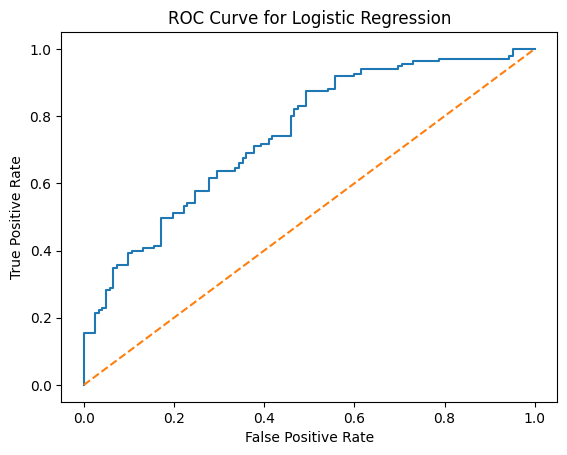

Logistic Regression ROC-AUC: 0.7449908925318761


In [ ]:

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    logreg_prob
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Logistic Regression")

plt.show()

#report the AUC
print("Logistic Regression ROC-AUC:", roc_auc_score(y_test, logreg_prob))

#6. ROC and AUC

#6. ROC and AUC for Logistic Regression

I plotted the ROC curve for logistic regression, which was the best model from our recall and specificty trade-off, and its ROC-AUC on the test data is 0.745. The ROC curve tells us the true positive rate (recall) against the false positive rate (1 minus specificity) at every possible threshold. Basically,ROC shows us how well a model can tell the difference between patients with and without heart disease at different decision thresholds. AUC is a single score that summarizes how well the model separates the two groups, where a score closer to 1 means better performance. An AUC of 0.745 means logistic regression has real signal but only a moderate ability to separate patients with and without heart disease.

#7. Final Analysis

##Compare the Performance of Your Classifiers
 All of the four models had nearly the same accuracy (about 0.67 to 0.68) at a threshold of 0.35, so the differences that have the most impact on the performance of our classifiers will be recall and specificity. Logistic regression and LDA caught the most patients with heart disease (recall 0.941 and 0.926) but flagged the most healthy patients (specificity 0.377 and 0.402). QDA and KNN flagged fewer healthy patients (specificity 0.590 and 0.516) but missed more patients with heart disease (33 and 24 missed). KNN had the highest ROC-AUC (0.816),followed by QDA (0.767), then logistic regression and LDA (both 0.745). Logistic regression and LDA performed almost identically, which is expected because they both use a linear decision boundary.

##Model Choice: Logistic Regression

I would deploy logistic regression, as a potential screening model. In the context of our dataset, the most serious mistake in my opinion, is failing to identify someone who has heart disease, so I put the most weight on the recall score. Logistic regression had the highest recall (0.941) and the fewest missed patients (8), compared with 10 for LDA, 24 for KNN and 33 for QDA. Accuracy was almost the same across all of our four models (about 0.67 to 0.68), so accuracy could not separate the models, but recall could. So our model could screen the paitents rather than being a sole diagnostic tool because of its low specificity.

Logistic regression also fits our dataset well for other reasons. It does not need normal distribuition for our predictors, which matters because sex is binary, and its coefficients are easy to explain. LDA performed almost the same, but logistic regression makes fewer assumptions. KNN had the highest ROC-AUC (0.816), but it had lower recall. QDA had the best specificity, but missing 33 patients with heart disease is too costly. Like we say, if we are choosing between models we should choose the simpler model, and the numbers work out in logistic regression's favor.

The main weakness is the specificity of our models. Logistic regression had the lowest specificity (0.377), so it flagged 76 of 122 healthy patients. I accept this because an unnecessary follow-up test is a much smaller harm than a missed diagnosis, but it means this model would work as a screening tool and not as a final diagnosis. Using only four predictors likely limits how well it can separate the two groups.

##Explain One Limitation of Your Analysis

One limitation of my analysis was my dataset. When looking at the website for it, it said we only have 303 unique instances, when our dataset here has over 1000 oberservations in total, which led me to believe that two different patients could have identical values, but, I could not confirm these are repeated records and I kept them because that's what I was told. However, most rows appear exactly 3 or 4 times, which suggests they could be repeats. If they are, the same patient can appear in both the training and test sets, so my test results could look better than they would on new patients. This affects KNN the most, because it can match a test patient to an identical training patient, so its ROC-AUC in particular may be inflated.

##Additional information I want before real-world use

Before using this model in the real-world or in practice, I would want more predictors that are strongly related to heart disease, such as chest pain type, maximum heart rate, and other's since my model only uses age, sex, resting blood pressure and cholesterol. I would also want confirmation of whether the duplicate rows are the same patients, a larger sample (this dataset has only 303 distinct patients, I think), and I would love to test it on other paitients from other hospitals, to check that my model works. Finally, I would want input from clinicians on how costly a missed diagnosis is compared with an unnecessary follow-up, so the threshold can be chosen based on the real cost trade-off instead of my judgment. After all of this, I truly think that my linear regression model should be used as a screening tool, because of it's recall and specificity scores, but also because of the nature of the dataset.

#Sources

[https://archive.ics.uci.edu/dataset/45/heart%2BdiseaseHeart?](https://archive.ics.uci.edu/dataset/45/heart%2BdiseaseHeart?)

[https://www.heart.org/en/health-topics/high-blood-pressure/understanding-blood-pressure-readings](https://www.heart.org/en/health-topics/high-blood-pressure/understanding-blood-pressure-readings)

